# Customer, engagement and revenue exploration

All findings describe synthetic data. Driver comparisons are observational. Current customer characteristics and historical monthly exposure answer different questions.

In [1]:
from pathlib import Path
import sys, json
root = Path.cwd()
if not (root / 'scripts').exists():
    root = root.parent
assert (root / 'scripts').exists(), 'Open this notebook inside the project'
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import pandas as pd
from scripts.common import ROOT, AS_OF, read_csv
from IPython.display import display, Image


In [2]:
c = read_csv('customers_clean')
s = read_csv('monthly_snapshots')
k = json.loads((ROOT/'outputs/executive_kpis.json').read_text())
display(pd.Series(k))

as_of_date                                    2026-08-31
currency                                             USD
total_customers                                    11880
active_customers                                    8531
churned_customers                                   3349
cumulative_churn_rate                           0.281902
active_customer_share                           0.718098
latest_month_churn_rate                         0.029755
latest_month_retention_rate                     0.970245
average_customer_tenure_months                  8.607787
monthly_recurring_revenue                       458229.6
arpu                                           53.713469
latest_month_churned_mrr                        15176.45
total_mrr_removed_at_churn_events              181689.85
revenue_at_risk                                 11977.55
latest_month_renewal_rate                       0.966261
average_support_tickets_latest_observation      1.242929
average_monthly_usage_latest_ob

In [3]:
summary = c.groupby('plan_type').agg(customers=('customer_id','size'),active_mrr=('active_mrr','sum'),average_clv=('observed_clv','mean'))
display(summary)
assert abs(summary.active_mrr.sum()-k['monthly_recurring_revenue']) < .01

,customers,active_mrr,average_clv
plan_type,,,
Basic,4920,97685.05,235.085913
Premium,2435,179550.25,917.970357
Standard,4525,180994.30,481.317801


## Use prior-month signals for driver analysis

A customer active at month end contributes an exposure only if the next calendar month is observed. The target is next-month cancellation. Customers can contribute multiple exposures.

In [4]:
drivers = read_csv('churn_driver_associations')
display(drivers[drivers.driver.isin(['engagement_band','payment_failures','support_ticket_band'])].sort_values(['driver','next_month_churn_rate'],ascending=[True,False]))

,driver,category,exposures,distinct_customers,next_month_churns,next_month_churn_rate
9740,engagement_band,Low,13893,4863,834,0.060030
9741,engagement_band,Medium,45600,9378,1471,0.032259
9739,engagement_band,High,36485,8031,583,0.015979
17,payment_failures,2,1731,1469,85,0.049105
16,payment_failures,1,18188,7495,617,0.033923
18,payment_failures,3,65,65,2,0.030769
15,payment_failures,0,75994,10471,2184,0.028739
9744,support_ticket_band,3+,11842,5309,514,0.043405
9743,support_ticket_band,1-2,48273,9854,1456,0.030162
9742,support_ticket_band,0,35863,8729,918,0.025597


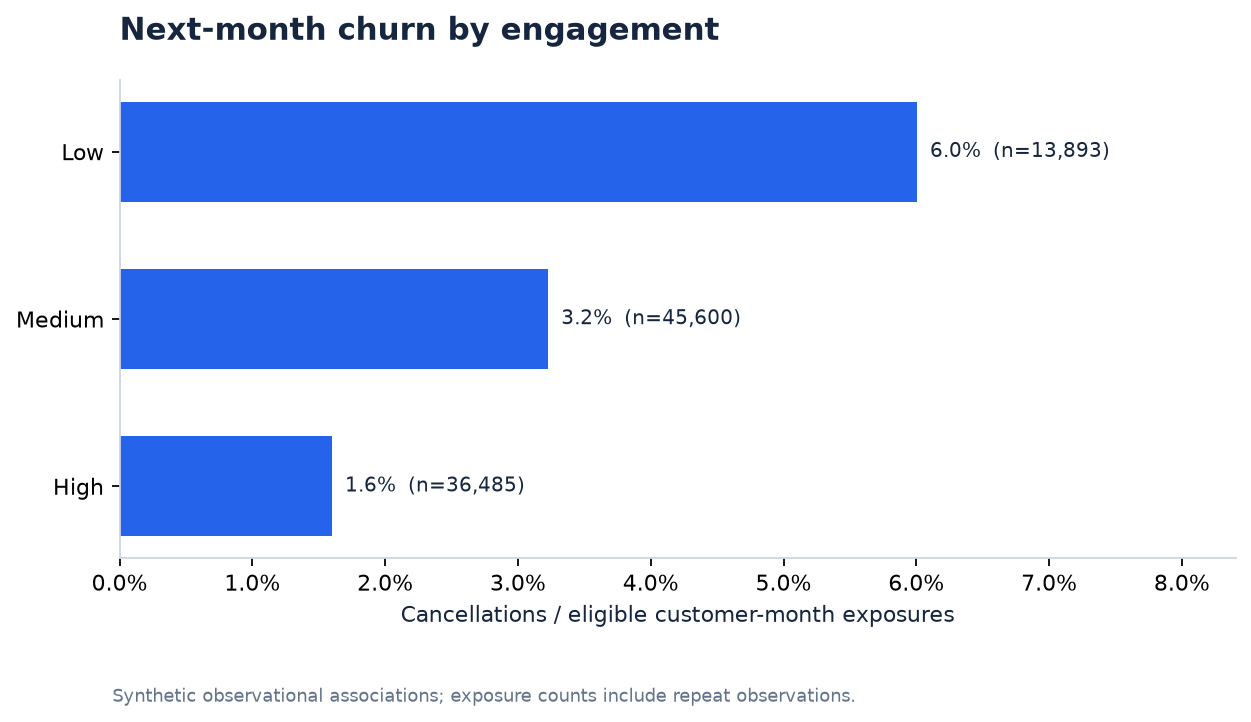

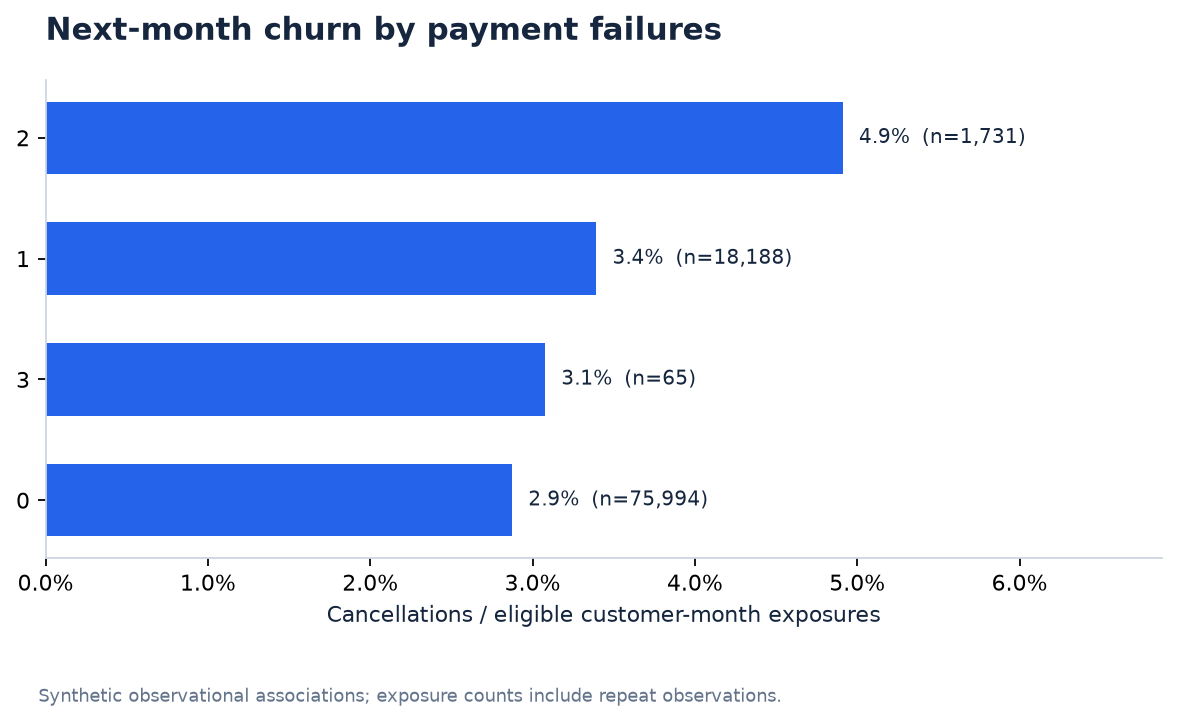

In [5]:
display(Image(filename=str(ROOT/'outputs/charts/churn_by_engagement.png')))
display(Image(filename=str(ROOT/'outputs/charts/churn_by_payment_failures.png')))

## Revenue interpretation

MRR is a monthly stock, observed CLV is historical earned revenue, and MRR at risk is an intervention pool. None of these establishes saved revenue. Acquisition spend and costs are absent.

,customers,mrr,mean_clv
customer_segment,,,
Core Customers,2448,131022.70,540.976712
New Customers,1765,93830.65,87.175666
Highly Engaged,1394,74504.10,395.131930
Loyal Standard,1412,58078.45,718.171176
Low Engagement,929,50546.25,653.270721
Loyal High Value,371,38269.90,1817.813127
At Risk,166,7181.55,461.141687
High Value At Risk,46,4796.00,1105.593913
Churned High Value,696,0.00,656.537241


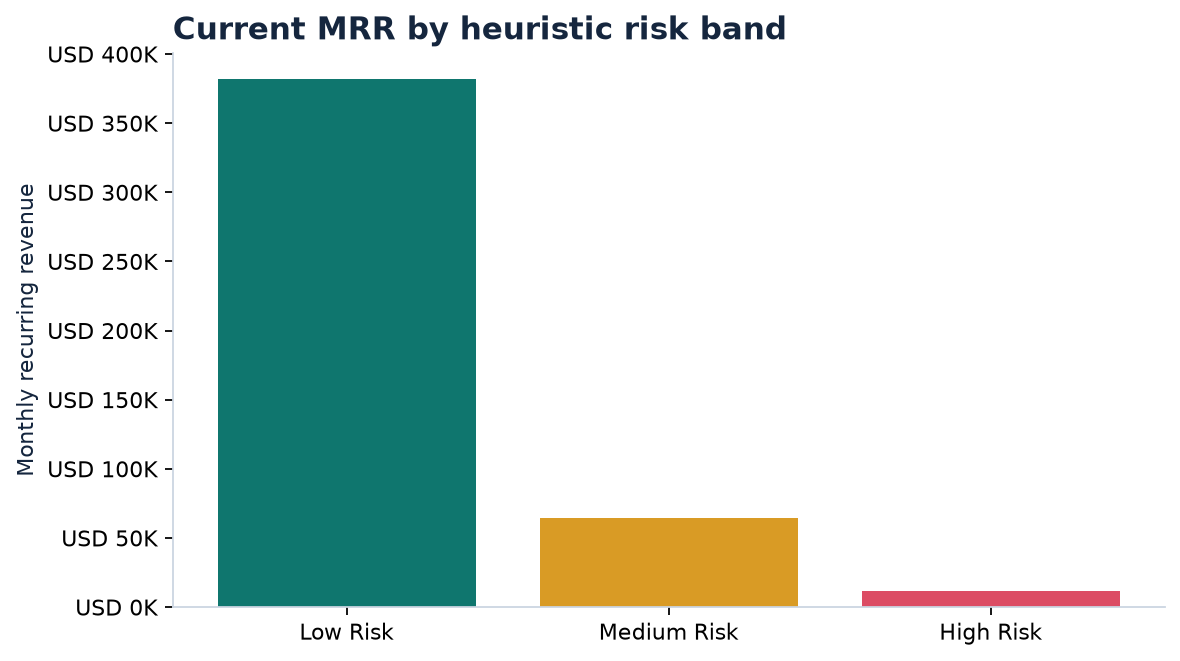

In [6]:
display(c.groupby('customer_segment').agg(customers=('customer_id','size'),mrr=('active_mrr','sum'),mean_clv=('observed_clv','mean')).sort_values('mrr',ascending=False))
display(Image(filename=str(ROOT/'outputs/charts/revenue_by_risk.png')))